<a href="https://colab.research.google.com/github/loki25590/handwritten-digit-recognition/blob/main/Handwritten_Digit_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys

print("Python Version:", sys.version)

Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("NumPy Version:", np.__version__)
print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

NumPy Version: 2.1.3
TensorFlow Version: 2.21.0
GPU Available: []


In [ ]:
# Load MNIST dataset

mnist = tf.keras.datasets.mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


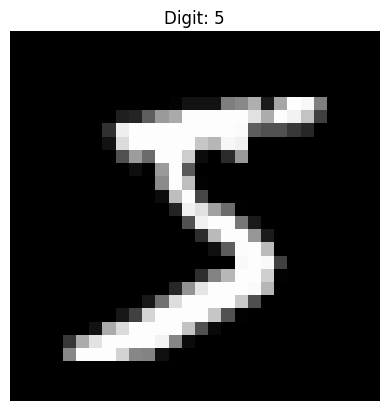

In [ ]:
# Display the first image

plt.imshow(X_train[0], cmap='gray')

plt.title(f"Digit: {y_train[0]}")

plt.axis('off')

plt.show()

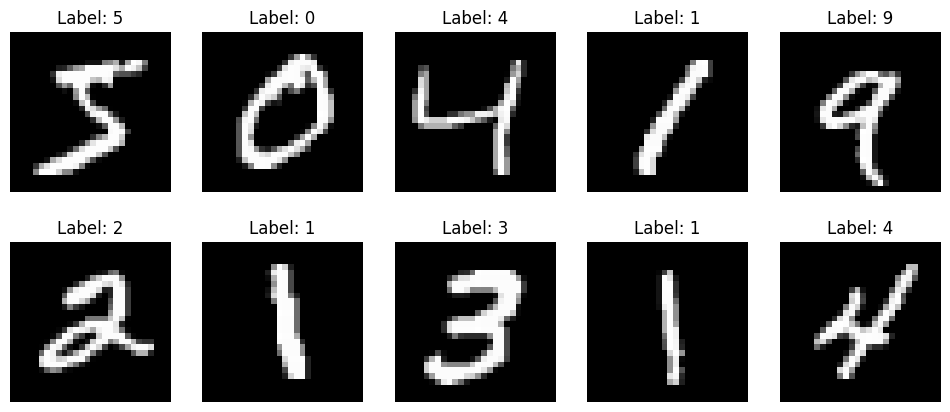

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i], cmap='gray')

    plt.title(f"Label: {y_train[i]}")

    plt.axis('off')

plt.show()

In [ ]:
print("Image shape:", X_train[0].shape)

print("Minimum pixel value:", X_train[0].min())

print("Maximum pixel value:", X_train[0].max())

print("First image pixel values:")
print(X_train[0])

Image shape: (28, 28)
Minimum pixel value: 0
Maximum pixel value: 255
First image pixel values:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  

In [ ]:
# Normalize pixel values

X_train = X_train / 255.0
X_test = X_test / 255.0

print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Minimum: 0.0
Maximum: 1.0


In [ ]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation='relu'
    ),

    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation='relu'
    ),

    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(10, activation='softmax')

])

In [ ]:
model.compile(

    optimizer='adam',

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


In [ ]:
history = model.fit(

    X_train,
    y_train,

    epochs=5,

    batch_size=64,

    validation_split=0.1

)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 52ms/step - accuracy: 0.9479 - loss: 0.1734 - val_accuracy: 0.9850 - val_loss: 0.0537
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 79s 49ms/step - accuracy: 0.9841 - loss: 0.0505 - val_accuracy: 0.9853 - val_loss: 0.0484
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 49ms/step - accuracy: 0.9895 - loss: 0.0335 - val_accuracy: 0.9887 - val_loss: 0.0378
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 49ms/step - accuracy: 0.9912 - loss: 0.0266 - val_accuracy: 0.9873 - val_loss: 0.0427
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 49ms/step - accuracy: 0.9936 - loss: 0.0193 - val_accuracy: 0.9902 - val_loss: 0.0379


In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9910 - loss: 0.0293
Test Accuracy: 99.09999966621399 %
Test Loss: 0.029304271563887596


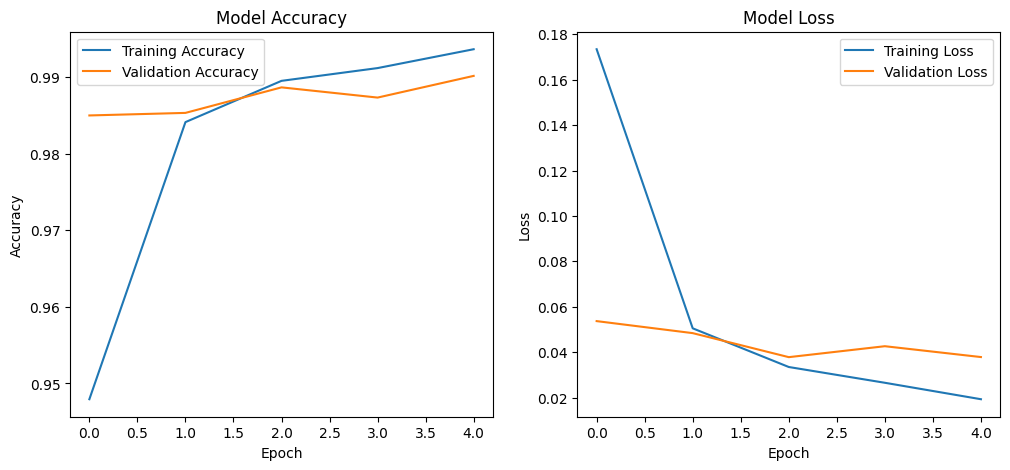

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [ ]:
predictions = model.predict(X_test[:10])

predicted_digits = np.argmax(predictions, axis=1)

print("Predicted:", predicted_digits)
print("Actual:   ", y_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
Predicted: [7 2 1 0 4 1 4 9 5 9]
Actual:    [7 2 1 0 4 1 4 9 5 9]


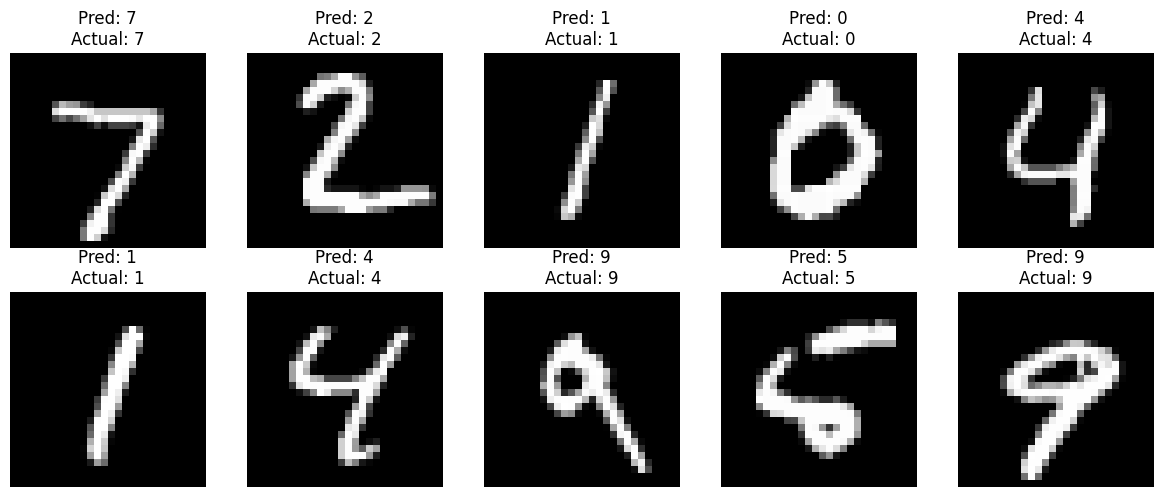

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        f"Pred: {predicted_digits[i]}\nActual: {y_test[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
model.save("digit_recognition_model.keras")

In [ ]:
from google.colab import files

files.download("digit_recognition_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install streamlit streamlit-drawable-canvas opencv-python-headless

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 51.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 74.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [streamlit-drawable-canvas]


In [ ]:

%%writefile app.py

import streamlit as st
import tensorflow as tf
import numpy as np
import cv2
from streamlit_drawable_canvas import st_canvas

st.set_page_config(
    page_title="Digit AI | Handwriting Recognition",
    page_icon="🔢",
    layout="wide"
)

# Load trained CNN model
@st.cache_resource
def load_model():
    return tf.keras.models.load_model("digit_recognition_model.keras")

model = load_model()

# Custom styling
st.markdown("""
<style>
.stApp {
    background: #0e1117;
    color: white;
}
.main-title {
    text-align: center;
    font-size: 42px;
    font-weight: bold;
    color: #58a6ff;
}
.subtitle {
    text-align: center;
    color: #aab4c3;
    font-size: 17px;
}
.result-card {
    background: #1c2333;
    padding: 25px;
    border-radius: 15px;
    text-align: center;
    border: 1px solid #303b50;
}
</style>
""", unsafe_allow_html=True)

# Header
st.markdown(
    '<div class="main-title">🔢 Digit AI</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">Handwritten Digit Recognition using Deep Learning</div>',
    unsafe_allow_html=True
)

st.write("")
st.divider()

left, right = st.columns([1.2, 1])

# Drawing section
with left:
    st.subheader("✍️ Draw Your Digit")
    st.write("Draw a number between 0 and 9.")

    canvas_result = st_canvas(
        fill_color="rgba(0,0,0,0)",
        stroke_width=15,
        stroke_color="#FFFFFF",
        background_color="#000000",
        width=350,
        height=350,
        drawing_mode="freedraw",
        return_image_data=True,
        key="digit_canvas"
    )

    predict_button = st.button(
        "🚀 Predict Digit",
        use_container_width=True
    )

# Prediction section
with right:
    st.subheader("🤖 AI Prediction")

    if predict_button:

        if canvas_result.image_data is None:
            st.warning("Please draw a digit first.")

        else:
            # Convert canvas image
            image = canvas_result.image_data.astype(np.uint8)

            # Convert RGBA to grayscale
            gray = cv2.cvtColor(
                image,
                cv2.COLOR_RGBA2GRAY
            )

            # Find digit boundaries
            coords = cv2.findNonZero(gray)

            if coords is None:
                st.warning("Please draw a digit first.")

            else:
                x, y, w, h = cv2.boundingRect(coords)

                digit = gray[y:y+h, x:x+w]

                # Resize while maintaining aspect ratio
                size = 20
                scale = size / max(w, h)

                new_w = max(1, int(w * scale))
                new_h = max(1, int(h * scale))

                resized_digit = cv2.resize(
                    digit,
                    (new_w, new_h),
                    interpolation=cv2.INTER_AREA
                )

                # Create 28x28 black image
                processed_image = np.zeros(
                    (28, 28),
                    dtype=np.uint8
                )

                # Centre the digit
                x_offset = (28 - new_w) // 2
                y_offset = (28 - new_h) // 2

                processed_image[
                    y_offset:y_offset+new_h,
                    x_offset:x_offset+new_w
                ] = resized_digit

                # Normalize image
                processed = (
                    processed_image.astype("float32") / 255.0
                )

                # Reshape for CNN
                processed = processed.reshape(
                    1, 28, 28, 1
                )

                # Predict
                prediction = model.predict(
                    processed,
                    verbose=0
                )

                predicted_digit = int(
                    np.argmax(prediction[0])
                )

                confidence = float(
                    np.max(prediction[0]) * 100
                )

                # Top 3 predictions
                top_indices = np.argsort(
                    prediction[0]
                )[-3:][::-1]

                # Main result
                st.markdown(
                    f"""
                    <div class="result-card">
                        <p style="color:#aab4c3;">
                            PREDICTED DIGIT
                        </p>
                        <h1 style="font-size:90px;color:#58a6ff;">
                            {predicted_digit}
                        </h1>
                        <p style="font-size:20px;">
                            Confidence: {confidence:.2f}%
                        </p>
                    </div>
                    """,
                    unsafe_allow_html=True
                )

                # Top 3 results
                st.write("")
                st.subheader("🏆 Top 3 Predictions")

                for index in top_indices:
                    digit_label = int(index)
                    probability = float(
                        prediction[0][index] * 100
                    )

                    st.write(
                        f"**Digit {digit_label}:** "
                        f"{probability:.2f}%"
                    )

                # Probability chart
                st.write("")
                st.subheader("📊 Prediction Probabilities")

                st.bar_chart(prediction[0])

                # Show processed image
                st.write("")
                st.subheader("🔍 Processed CNN Input")

                st.image(
                    cv2.resize(
                        processed_image,
                        (280, 280),
                        interpolation=cv2.INTER_NEAREST
                    ),
                    caption="28 × 28 MNIST-style input",
                    width=220
                )

    else:
        st.info("Draw a digit and click Predict Digit.")

# Footer
st.divider()

st.caption(
    "Built with Python • TensorFlow • CNN • OpenCV • Streamlit"
)


Writing app.py


In [ ]:
%%writefile requirements.txt

tensorflow
numpy
opencv-python-headless
streamlit
streamlit-drawable-canvas
pillow

Writing requirements.txt


In [ ]:
import os

print(os.listdir())

['.config', 'digit_recognition_model.keras', 'requirements.txt', 'app.py', 'sample_data']


In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼
added 22 packages in 2s
⠼
⠼3 packages are looking for funding
⠼  run `npm fund` for details
⠼

In [ ]:
!streamlit run app.py &>/content/streamlit.log &

In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true > streamlit.log 2>&1 &

In [ ]:
import requests
import time

time.sleep(5)

response = requests.get("http://localhost:8501")

print("Status:", response.status_code)

Status: 200


In [ ]:
import requests

url = "https://quick-guests-like.loca.lt/static/js/BidiComponent.DBslL13W.js"

response = requests.get(
    url,
    headers={"bypass-tunnel-reminder": "true"}
)

print("Status:", response.status_code)
print("Content Type:", response.headers.get("content-type"))
print("Response:", response.text[:200])

Status: 502
Content Type: text/plain
Response: Bad Gateway


In [ ]:
!pip install pyngrok

In [ ]:
print("Token length:", len(token))
print("Contains whitespace:", any(c.isspace() for c in token))
print("Looks like a URL:", token.startswith("http"))

Token length: 189
Contains whitespace: True
Looks like a URL: False


In [ ]:
from pyngrok import ngrok
from getpass import getpass
import os

ngrok.kill()

config_path = "/root/.config/ngrok/ngrok.yml"

if os.path.exists(config_path):
    os.remove(config_path)

token = getpass("Enter your NEW ngrok Authtoken: ")
ngrok.set_auth_token(token.strip())

print("New token saved successfully!")

Enter your NEW ngrok Authtoken: ··········
New token saved successfully!


In [ ]:
public_url = ngrok.connect(8501)
print("Your application URL:", public_url)

Your application URL: NgrokTunnel: "https://retying-conceded-porridge.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
!curl -I http://127.0.0.1:8501

curl: (7) Failed to connect to 127.0.0.1 port 8501 after 0 ms: Couldn't connect to server


In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true > streamlit.log 2>&1 &

In [ ]:
!curl -I http://127.0.0.1:8501

HTTP/1.1 200 OK
date: Sun, 01 Nov 2026 16:36:27 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Sun, 01 Nov 2026 16:09:26 GMT
etag: "d1beaa5a92a1391c29228616b086bd67"
cache-control: no-cache



In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true > streamlit.log 2>&1 &

In [ ]:
import shutil

shutil.copy("app.py", "app_backup.py")

print("Backup created successfully!")

Backup created successfully!


In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

Test Accuracy: 99.1 %
Test Loss: 0.0293


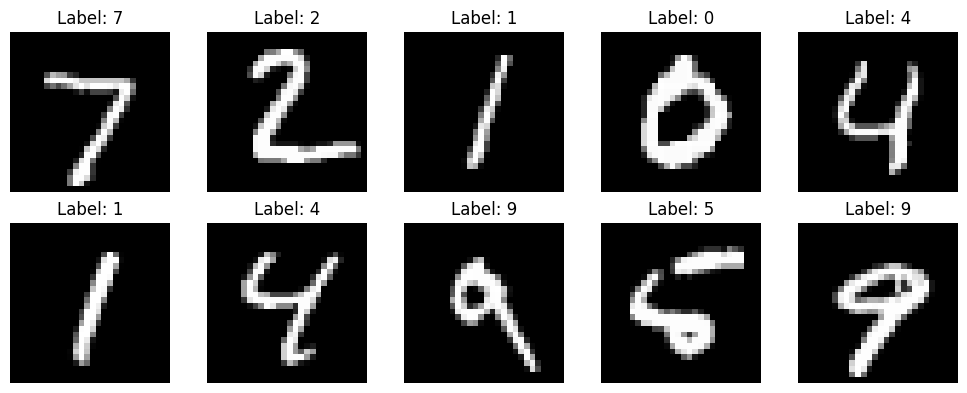

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y_test[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

files = [
    "app.py",
    "digit_recognition_model.keras",
    "requirements.txt"
]

for file in files:
    if os.path.exists(file):
        size = os.path.getsize(file) / (1024 * 1024)
        print(f"✅ {file} — {size:.2f} MB")
    else:
        print(f"❌ Missing: {file}")

✅ app.py — 0.00 MB
✅ digit_recognition_model.keras — 2.61 MB
✅ requirements.txt — 0.00 MB


In [ ]:
from google.colab import files

files.download("app.py")
files.download("digit_recognition_model.keras")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>